# 05 — Selección y entrenamiento del modelo clasificativo

## ¿Qué voy a hacer en este notebook?

Ya preparé variables y periodos sin fuga temporal. En PaySim, `step` representa la **hora simulada** de cada transacción (`1 step` = `1 hora`); lo usé para separar pasado y futuro, pero no entra como variable del modelo.

Ahora voy a escoger y entrenar **un solo modelo** para asignar una probabilidad de fraude a cada transacción.

Mi decisión es entrenar un **Random Forest clasificativo**. La etiqueta `isFraud` tiene dos valores (`0` o `1`), por eso el problema es de clasificación y no de regresión.

In [3]:
from pathlib import Path
import sys
import pandas as pd

PROJECT_ROOT = Path('..').resolve()
sys.path.insert(0, str(PROJECT_ROOT / 'src'))
DATA_RAW = PROJECT_ROOT / 'data' / 'raw' / 'paysim.csv'
IMAGES_DIR = PROJECT_ROOT / 'images'
REPORTS_DIR = PROJECT_ROOT / 'reports'
MODELS_DIR = PROJECT_ROOT / 'models'
OUTPUTS_DIR = PROJECT_ROOT / 'data' / 'outputs'
PROCESSED_DIR = PROJECT_ROOT / 'data' / 'processed'
for folder in [IMAGES_DIR, REPORTS_DIR, MODELS_DIR, OUTPUTS_DIR, PROCESSED_DIR]:
    folder.mkdir(parents=True, exist_ok=True)


In [4]:
import pandas as pd
from modeling_utils import (
    ALERT_COLUMN, CATEGORICAL_FEATURES, MODEL_FEATURES, NUMERIC_FEATURES, TARGET,
    TRAIN_END_STEP, VALIDATION_END_STEP, engineer_features, load_transactions,
    split_summary, temporal_split, training_sample, xy,
)

raw = load_transactions(DATA_RAW)
data = engineer_features(raw)
train, validation, test = temporal_split(data)
summary = split_summary(train, validation, test)
summary


,transacciones,fraudes,tasa_fraude_pct,step_min,step_max
periodo,,,,,
train,4463587,3643,0.0816,1,323
validation,980416,564,0.0575,324,378
test,918617,4006,0.4361,379,743


## ¿Por qué escojo Random Forest?

Antes de entrenar, comparo conceptualmente las alternativas razonables:

| Modelo posible | Qué aportaría | Decisión en este proyecto |
|---|---|---|
| Regresión logística | Explicación lineal y rápida | No la entreno: puede no capturar combinaciones no lineales de monto, tipo y saldos. |
| Árbol único | Reglas fáciles de leer | No lo entreno: puede ser inestable y sobreajustar. |
| Gradient boosting | Suele rendir bien en tablas | No lo entreno: exige una búsqueda y explicación más complejas que el alcance actual. |
| **Random Forest** | Combina árboles, captura interacciones y admite pesos por clase | **Lo entreno como único modelo de esta entrega.** |

Esta elección no significa que Random Forest sea siempre el mejor modelo. Es una decisión razonada para mi primer modelo: puedo representar patrones no lineales del EDA, darle más importancia al fraude escaso y luego revisar qué variables influyen más.

## Preparación para entrenar

Uso únicamente la muestra de `train`: todos los fraudes históricos disponibles en ese periodo y una muestra reproducible de operaciones legítimas. `validation` queda completa y solo se utiliza después para definir el umbral de alerta.

In [6]:
from modeling_utils import build_random_forest_pipeline  # importa la función que construye el pipeline del modelo

train_sample = training_sample(train)  # toma una muestra reproducible de 'train' para entrenar con menos datos pero manteniendo el patrón. La cual es balanceada
X_train, y_train = xy(train_sample)  # separa las variables de entrada (X) y la etiqueta objetivo (y) en la muestra de entrenamiento
X_validation, y_validation = xy(validation)  # separa X e y del conjunto de validación completo, sin muestrear
print(f'Entrenamiento usado por el modelo: {len(X_train):,} filas | fraudes: {int(y_train.sum()):,}')  # muestra cuántas filas y fraudes se usarán para entrenar
print(f'Validación sin muestrear: {len(X_validation):,} filas | fraudes: {int(y_validation.sum()):,}')  # muestra el tamaño de validación y cuántos fraudes contiene

model = build_random_forest_pipeline()  # crea el pipeline con preprocesamiento y Random Forest configurado
model  # muestra el objeto del modelo para verificar su estructura

# ¿Por qué se hace así?
# Se entrena con una muestra de 'train' para reducir el costo computacional y controlar el tiempo de ejecución.
# Se usa 'validation' completa para evaluar el modelo con datos no vistos y seleccionar el umbral sin fuga temporal.
# El pipeline centraliza el preprocesamiento y el modelo en un solo objeto, lo que facilita entrenar, evaluar y guardar el artefacto.

Entrenamiento usado por el modelo: 76,503 filas | fraudes: 3,643
Validación sin muestrear: 980,416 filas | fraudes: 564


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessing', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('type', ...), ('numeric', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transform

## Entrenamiento del único modelo

El parámetro `class_weight='balanced_subsample'` hace que cada árbol preste más atención a la clase fraudulenta, que es minoritaria. Limito profundidad y tamaño mínimo de hoja para reducir sobreajuste, y fijo `random_state` para poder reproducir el resultado.

In [7]:
# Ajusta el pipeline completo (preprocesamiento + RandomForest) usando la muestra de entrenamiento.
# model.fit(X_train, y_train) hace:
#  - en el paso 'preprocessing' del pipeline: aprende/ajusta los transformadores (por ejemplo, OneHotEncoder) con X_train.
#  - en el paso 'model' del pipeline: entrena el RandomForest con las características transformadas y las etiquetas y_train.
model.fit(X_train, y_train) #se hace el entrenameinto del modelo con los datos de entrenamiento

# Calcula la probabilidad de que cada observación de validación sea fraude.
# model.predict_proba(X_validation) devuelve una matriz de forma (n_muestras, n_clases);
# la columna 1 corresponde a la probabilidad de la clase positiva (isFraud == 1).
validation_probability = model.predict_proba(X_validation)[:, 1]

# Mensaje informativo para el usuario indicando que el modelo se entrenó y que se generaron probabilidades para validación.
print('Modelo Random Forest entrenado. Probabilidades generadas solo para validation.')

# Por qué se hace esto:
#  - Entrenar el pipeline asegura que el preprocesamiento y el modelo se ajusten de forma coherente y reproducible.
#  - Obtener probabilidades en validation permite seleccionar un umbral (por ejemplo optimizando F2) y evaluar métricas
#    sin filtrar ni muestrear el conjunto de validación (evita fuga temporal y refleja desempeño real en ese periodo).

Modelo Random Forest entrenado. Probabilidades generadas solo para validation.


## Elección del umbral con validación

Una probabilidad necesita un punto de corte para convertirse en alerta. No uso automáticamente `0.50`, porque en fraude la clase positiva es muy rara y perder un fraude puede ser más costoso que revisar una alerta adicional.

Selecciono el umbral que maximiza **F2** en `validation`: esta métrica da más peso al *recall* (capturar fraudes) sin olvidar la precisión. El conjunto `test` sigue sin participar en ninguna decisión.

In [8]:
from modeling_utils import metric_summary, select_f2_threshold

threshold, validation_curve = select_f2_threshold(y_validation, validation_probability)
validation_metrics = metric_summary(validation, validation_probability, threshold, 'Random Forest - validation')
print(f'Umbral seleccionado con validation: {threshold:.6f}')
validation_metrics[['precision', 'recall', 'f2', 'average_precision', 'verdaderos_positivos', 'falsos_positivos', 'falsos_negativos']]

Umbral seleccionado con validation: 0.858498


precision               1.0
recall                  1.0
f2                      1.0
average_precision       1.0
verdaderos_positivos    564
falsos_positivos          0
falsos_negativos          0
dtype: object

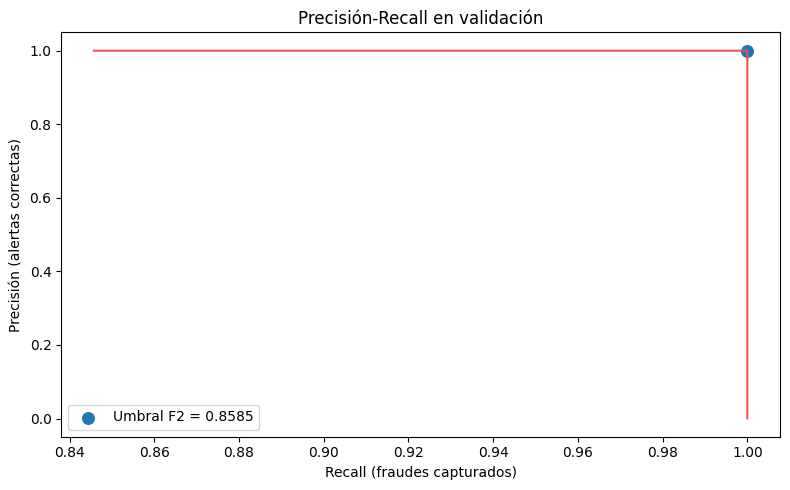

Gráfico guardado: /home/johanrobles/Documentos/Idea/analisis-fraude-&-modelo-predictivo-datasetPaySim/images/model_validation_precision_recall.png


In [9]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(validation_curve['recall'], validation_curve['precision'], color='#e45756')
selected = validation_curve.loc[validation_curve['f2'].idxmax()]
ax.scatter(selected['recall'], selected['precision'], color='#1f77b4', s=70, label=f'Umbral F2 = {threshold:.4f}')
ax.set_title('Precisión-Recall en validación')
ax.set_xlabel('Recall (fraudes capturados)')
ax.set_ylabel('Precisión (alertas correctas)')
ax.legend()
plt.tight_layout()
validation_plot = IMAGES_DIR / 'model_validation_precision_recall.png'
plt.savefig(validation_plot, bbox_inches='tight')
plt.show()
print('Gráfico guardado:', validation_plot)

## Interpretación de variables

Random Forest no produce una fórmula lineal, pero sí permite observar qué variables utilizó con más frecuencia para separar casos. Esto no demuestra causalidad; me ayuda a comprobar si el modelo está apoyándose en señales coherentes con el análisis exploratorio.

In [10]:
import pandas as pd

feature_names = model.named_steps['preprocessing'].get_feature_names_out()
importance = pd.Series(model.named_steps['model'].feature_importances_, index=feature_names).sort_values(ascending=False)
top_importance = importance.head(12)
top_importance

numeric__balance_error_origin        0.242636
numeric__amount_to_origin_balance    0.198833
numeric__origin_balance_diff         0.185371
numeric__newbalanceOrig              0.103765
numeric__is_origin_balance_zero      0.078835
numeric__oldbalanceOrg               0.054805
numeric__amount                      0.030710
type__type_PAYMENT                   0.027477
numeric__log_amount                  0.026466
type__type_TRANSFER                  0.012021
numeric__dest_balance_diff           0.009206
numeric__balance_error_dest          0.008006
dtype: float64

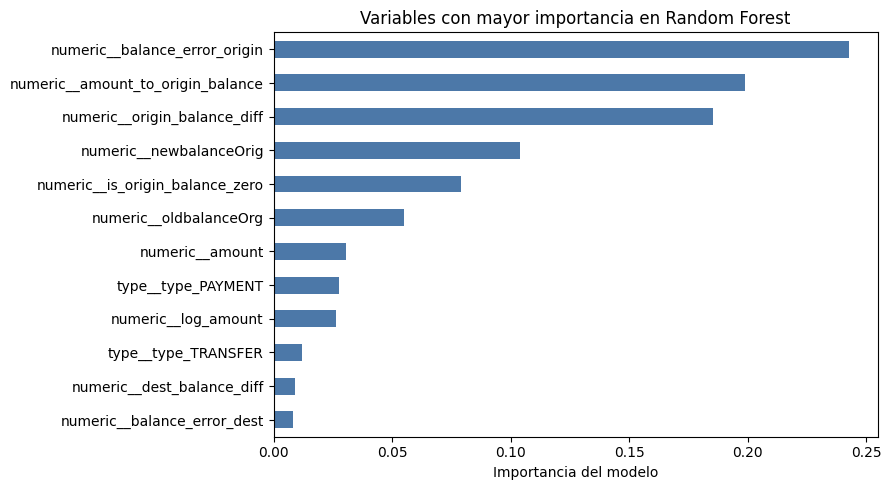

Gráfico guardado: /home/johanrobles/Documentos/Idea/analisis-fraude-&-modelo-predictivo-datasetPaySim/images/model_feature_importance.png


In [11]:
fig, ax = plt.subplots(figsize=(9, 5))
top_importance.sort_values().plot.barh(ax=ax, color='#4c78a8')
ax.set_title('Variables con mayor importancia en Random Forest')
ax.set_xlabel('Importancia del modelo')
plt.tight_layout()
importance_plot = IMAGES_DIR / 'model_feature_importance.png'
plt.savefig(importance_plot, bbox_inches='tight')
plt.show()
print('Gráfico guardado:', importance_plot)

## Guardar el artefacto para evaluar una sola vez

Guardo el pipeline completo y el umbral escogido. Así el notebook 06 no reentrena ni cambia decisiones al ver el periodo de prueba: únicamente aplica lo que ya quedó definido.

In [13]:
import json
import joblib

# Empaqueta el pipeline del modelo y la información necesaria para aplicarlo luego.
# - 'model': pipeline completo (preprocesamiento + RandomForest)
# - 'threshold': umbral seleccionado en validación para convertir probabilidad en alerta
# - 'features': lista de features originales antes de encoding (útil para confirmar inputs)
# - 'train_end_step' / 'validation_end_step': marcas temporales que definen particiones (evitan fuga)
# - 'validation_metrics': métricas calculadas en validation convertidas a dict (serializables)
bundle = { #lo que se guarda, noten que se guarda el modelo ya entrenado
    'model': model,
    'threshold': threshold,
    'features': MODEL_FEATURES,
    'train_end_step': TRAIN_END_STEP,
    'validation_end_step': VALIDATION_END_STEP,
    'validation_metrics': validation_metrics.to_dict(),
}

# Ruta donde se guardará el artefacto del modelo en formato joblib (eficiente para objetos grandes).
model_path = MODELS_DIR / 'random_forest_fraud.joblib'

# Serializa y escribe el bundle en disco. joblib.dump guarda objetos Python (a menudo más rápido que pickle puro).
joblib.dump(bundle, model_path)

# Metadatos ligeros en JSON para inspección rápida y tracking:
# - 'model': nombre del estimador (texto)
# - 'threshold_selected_on_validation': el umbral elegido en validación
# - 'train_rows_sampled': filas usadas para el entrenamiento (muestra reproducible)
# - 'validation_rows_full': tamaño de validación completo utilizado para seleccionar el umbral
metadata = {
    'model': 'RandomForestClassifier',
    'threshold_selected_on_validation': threshold,
    'train_rows_sampled': len(train_sample),
    'validation_rows_full': len(validation),
    'feature_count_before_encoding': len(MODEL_FEATURES),
}

# Escribe metadatos en OUTPUTS_DIR como JSON legible.
(OUTPUTS_DIR / 'model_metadata.json').write_text(json.dumps(metadata, indent=2), encoding='utf-8')

# Mensajes informativos para el usuario/notebook.
print('Modelo guardado en:', model_path)
print('Metadatos guardados en:', OUTPUTS_DIR / 'model_metadata.json')

# Por qué se hace:
# Guardar el pipeline completo y el umbral permite reproducibilidad y evita reentrenar o cambiar decisiones
# cuando se evalúe en el periodo test (notebook 06) o en producción. El bundle conserva el preprocesamiento
# necesario para transformar nuevas transacciones exactamente igual que en entrenamiento. Los metadatos JSON
# proporcionan un resumen ligero para auditoría, trazabilidad y despliegue sin cargar objetos pesados.

Modelo guardado en: /home/johanrobles/Documentos/Idea/analisis-fraude-&-modelo-predictivo-datasetPaySim/models/random_forest_fraud.joblib
Metadatos guardados en: /home/johanrobles/Documentos/Idea/analisis-fraude-&-modelo-predictivo-datasetPaySim/data/outputs/model_metadata.json


In [14]:
print(
    f'Conclusión de entrenamiento: seleccioné Random Forest y un umbral de {threshold:.6f} usando únicamente validation. '
    f'En ese periodo el recall fue {validation_metrics["recall"]:.2%} y la precisión {validation_metrics["precision"]:.2%}. '
    'Todavía no concluyo desempeño final: esa comprobación corresponde al periodo test en el notebook 06.'
)

Conclusión de entrenamiento: seleccioné Random Forest y un umbral de 0.858498 usando únicamente validation. En ese periodo el recall fue 100.00% y la precisión 100.00%. Todavía no concluyo desempeño final: esa comprobación corresponde al periodo test en el notebook 06.


## Siguiente paso

Abriré `06_model_evaluation_interpretation.ipynb` para evaluar el modelo ya congelado sobre transacciones futuras y compararlo con la alerta original `isFlaggedFraud`.

Si la validación muestra métricas casi perfectas, las interpretaré con cautela: el dataset es sintético y las señales de saldo posteriores pueden simplificar el patrón.